In [4]:
import pandas as pd
from urllib.parse import quote

path = "data/Sample - Superstore.xls (1)/Sample - Superstore.xls"
url = "https://raw.githubusercontent.com/divyachakrawarti27/Superstore-Sales-Analytics/main/" + quote(path)

df = pd.read_excel(url, sheet_name="Orders")
print(df.shape)
df.head()


(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from urllib.parse import quote

sns.set_style("whitegrid")
os.makedirs("charts", exist_ok=True)

path = "data/Sample - Superstore.xls (1)/Sample - Superstore.xls"
url = "https://raw.githubusercontent.com/divyachakrawarti27/Superstore-Sales-Analytics/main/" + quote(path)
df = pd.read_excel(url, sheet_name="Orders")
print(df.shape)

(9994, 21)


In [7]:
print("Shape:", df.shape)
print("\nColumns and data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

Shape: (9994, 21)

Columns and data types:
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region         

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [8]:
# 1. Remove duplicates
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

# 2. Handle missing values (numeric -> median, text -> mode)
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ["float64", "int64"]:
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# 3. Fix data types
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df["Postal Code"] = df["Postal Code"].astype(str)

# 4. Clean text columns
for col in ["Customer Name", "City", "State"]:
    df[col] = df[col].str.strip().str.title()

# 5. Rename column
df = df.rename(columns={"Sub-Category": "SubCategory"})

# 6. Remove incorrect records (negative sales or quantity)
df = df[(df["Sales"] > 0) & (df["Quantity"] > 0)]

# 7. New columns for analysis
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Profit Margin"] = df["Profit"] / df["Sales"]

# 8. Drop unnecessary column
df = df.drop(columns=["Row ID"])

print("Final shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())
df.to_csv("superstore_cleaned.csv", index=False)
df.head()

Duplicates removed: 0
Final shape: (9994, 23)
Missing values left: 0


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Category,SubCategory,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Profit Margin
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,0.1600
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,0.3000
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,0.4700
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,-0.4000
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,0.1125


In [9]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [10]:
corr = df[["Sales", "Quantity", "Discount", "Profit"]].corr()
print(corr)

             Sales  Quantity  Discount    Profit
Sales     1.000000  0.200795 -0.028190  0.479064
Quantity  0.200795  1.000000  0.008623  0.066253
Discount -0.028190  0.008623  1.000000 -0.219487
Profit    0.479064  0.066253 -0.219487  1.000000


In [11]:
for col in ["Sales", "Profit"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n} outliers ({n/len(df)*100:.1f}%)  range = [{low:.2f}, {high:.2f}]")

Sales: 1167 outliers (11.7%)  range = [-271.71, 498.93]
Profit: 1881 outliers (18.8%)  range = [-39.72, 70.82]


In [12]:
print("Sales by Category:\n", df.groupby("Category")["Sales"].sum().sort_values(ascending=False), "\n")
print("Profit by Region:\n", df.groupby("Region")["Profit"].sum().sort_values(ascending=False), "\n")
print("Sales by Year:\n", df.groupby("Order Year")["Sales"].sum(), "\n")
print("Worst 5 SubCategories by Profit:\n", df.groupby("SubCategory")["Profit"].sum().sort_values().head(5))

Sales by Category:
 Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64 

Profit by Region:
 Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64 

Sales by Year:
 Order Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64 

Worst 5 SubCategories by Profit:
 SubCategory
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


/tmp/ipykernel_2115/2822319371.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=d.index, y=d.values, palette="Blues_r")


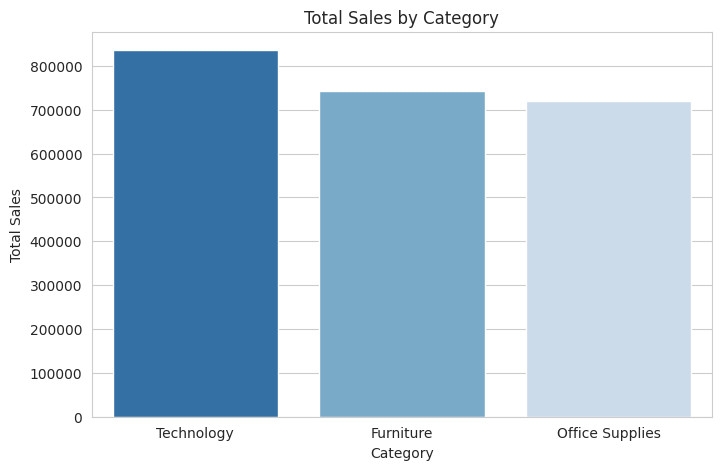

In [13]:
plt.figure(figsize=(8, 5))
d = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
sns.barplot(x=d.index, y=d.values, palette="Blues_r")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.savefig("charts/1_sales_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

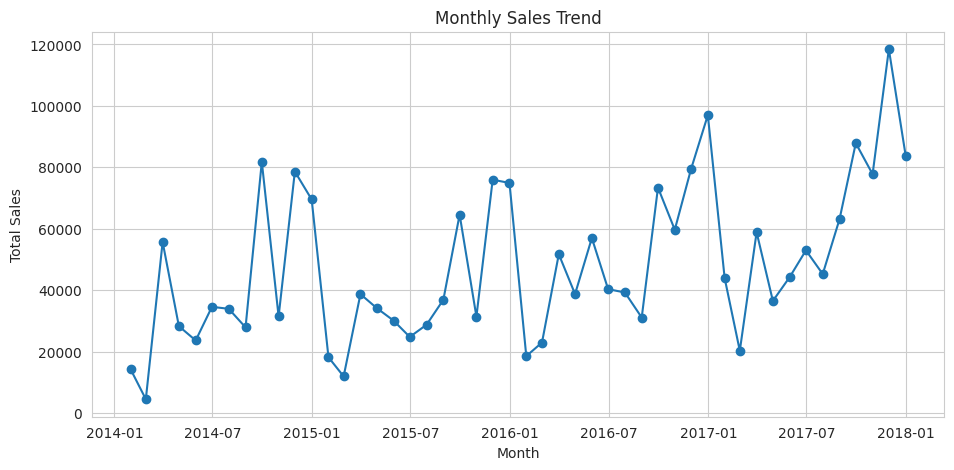

In [14]:
plt.figure(figsize=(11, 5))
m = df.set_index("Order Date").resample("ME")["Sales"].sum()
plt.plot(m.index, m.values, marker="o", color="#1f77b4")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.savefig("charts/2_monthly_sales_trend.png", dpi=150, bbox_inches="tight")
plt.show()

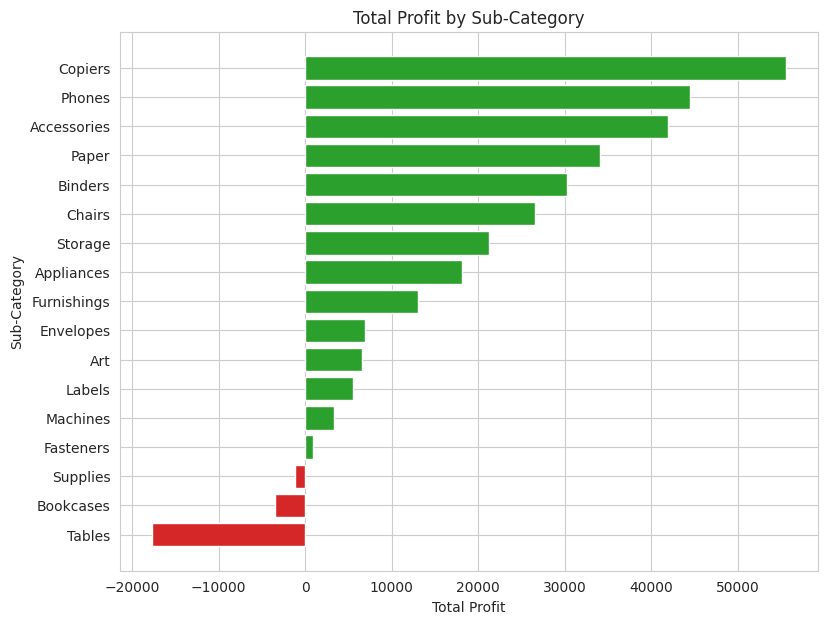

In [15]:
plt.figure(figsize=(9, 7))
p = df.groupby("SubCategory")["Profit"].sum().sort_values()
colors = ["#d62728" if v < 0 else "#2ca02c" for v in p.values]
plt.barh(p.index, p.values, color=colors)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.savefig("charts/3_profit_by_subcategory.png", dpi=150, bbox_inches="tight")
plt.show()

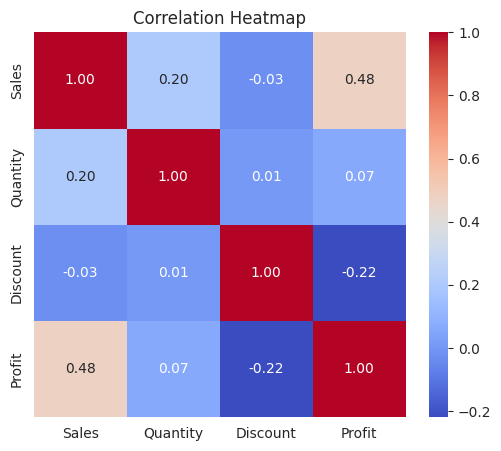

In [16]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("charts/4_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

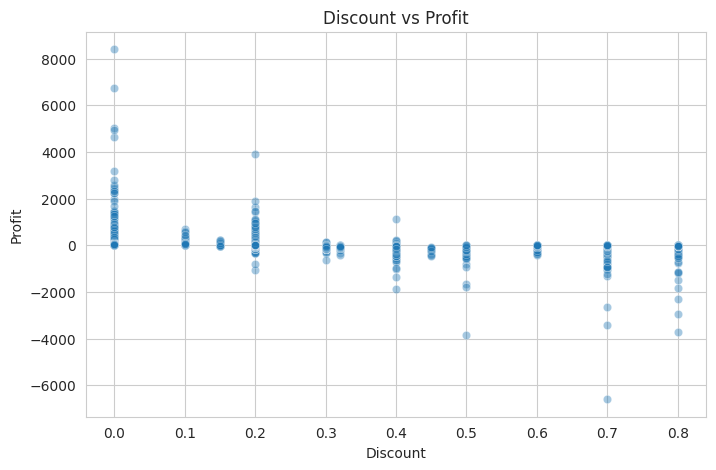

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.4)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.savefig("charts/5_discount_vs_profit.png", dpi=150, bbox_inches="tight")
plt.show()

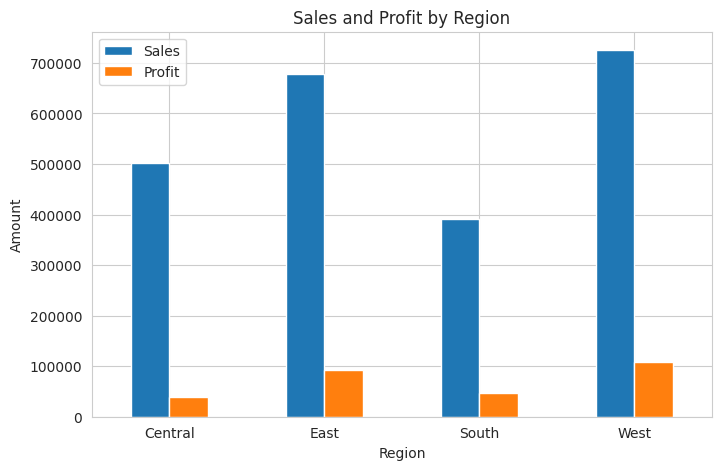

In [18]:
r = df.groupby("Region")[["Sales", "Profit"]].sum()
r.plot(kind="bar", figsize=(8, 5))
plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.savefig("charts/6_region_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
!zip -r charts.zip charts
from google.colab import files
files.download("charts.zip")
files.download("superstore_cleaned.csv")

  adding: charts/ (stored 0%)
  adding: charts/6_region_sales_profit.png (deflated 24%)
  adding: charts/2_monthly_sales_trend.png (deflated 7%)
  adding: charts/3_profit_by_subcategory.png (deflated 23%)
  adding: charts/1_sales_by_category.png (deflated 24%)
  adding: charts/5_discount_vs_profit.png (deflated 12%)
  adding: charts/4_correlation_heatmap.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>